<a href="https://colab.research.google.com/github/UlfanNayakaDipta/2026-Visi-Komputer/blob/main/jobsheet2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"ulfannayakadipta","key":"a536cc6510379b096aa5fc3a5ffaa1b9"}'}

In [3]:
import os, shutil
if os.path.exists("kaggle.json"):
    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    shutil.copy("kaggle.json", os.path.expanduser("~/.kaggle/kaggle.json"))
    os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
    !pip -q install kaggle
    print("Kaggle API siap.")
else:
    print("kaggle.json belum diupload.")

Kaggle API siap.


In [4]:
!kaggle datasets download -d pankrzysiu/cifar10-python -p /content -q
!unzip -q /content/cifar10-python.zip -d /content/cifar10_data
print("CIFAR-10 siap.")

Dataset URL: https://www.kaggle.com/datasets/pankrzysiu/cifar10-python
License(s): other
CIFAR-10 siap.


## D1 – Memulai Klasifikasi Gambar dengan MNIST

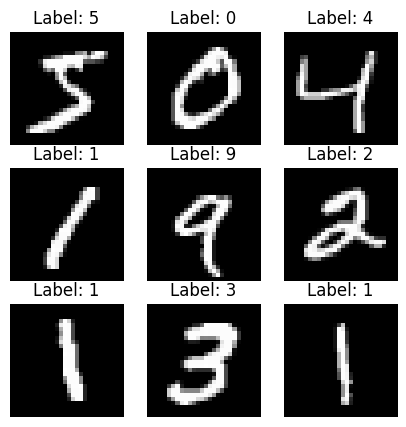

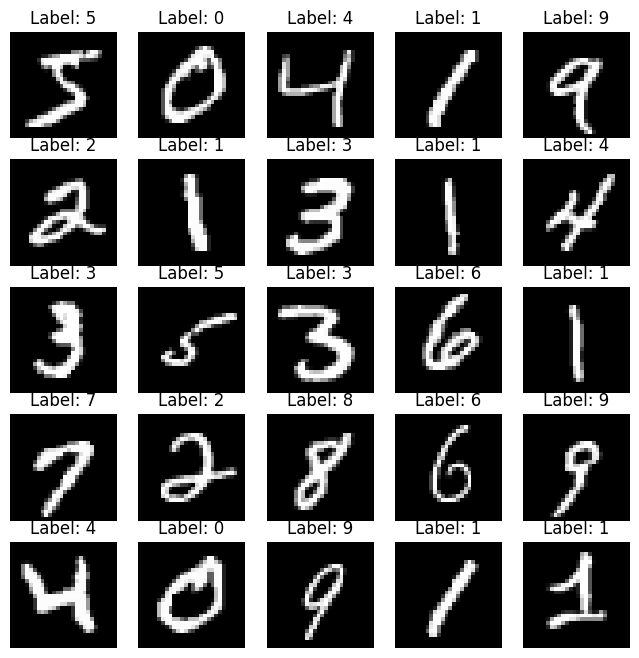

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()

plt.figure(figsize=(5,5))
for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.show()

plt.figure(figsize=(8,8))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.show()

## D2 – Klasifikasi Tradisional dengan SVM (MNIST)

In [6]:
from sklearn import svm
from sklearn.metrics import accuracy_score

x_train_flat = x_train.reshape(len(x_train), -1) / 255.0
x_test_flat = x_test.reshape(len(x_test), -1) / 255.0

clf = svm.SVC(kernel='linear', gamma='scale')
clf.fit(x_train_flat[:5000], y_train[:5000])
y_pred = clf.predict(x_test_flat)
print("Akurasi SVM linear:", accuracy_score(y_test, y_pred))

clf_rbf = svm.SVC(kernel='rbf', gamma='scale')
clf_rbf.fit(x_train_flat[:5000], y_train[:5000])
y_pred_rbf = clf_rbf.predict(x_test_flat)
print("Akurasi SVM RBF:", accuracy_score(y_test, y_pred_rbf))

Akurasi SVM linear: 0.9101
Akurasi SVM RBF: 0.9513


## D3 – CNN Sederhana (MNIST)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.9443 - loss: 0.1862 - val_accuracy: 0.9740 - val_loss: 0.0835
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9814 - loss: 0.0629 - val_accuracy: 0.9825 - val_loss: 0.0596
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9870 - loss: 0.0426 - val_accuracy: 0.9863 - val_loss: 0.0507
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9906 - loss: 0.0306 - val_accuracy: 0.9847 - val_loss: 0.0521
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9928 - loss: 0.0219 - val_accuracy: 0.9877 - val_loss: 0.0507


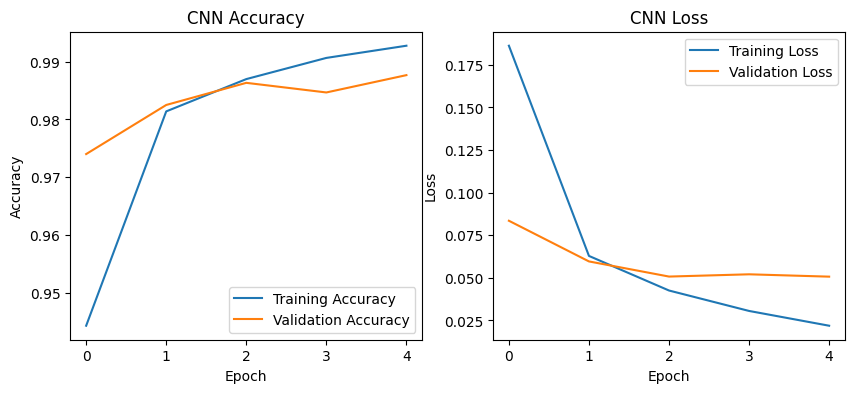

In [7]:
import tensorflow as tf
from tensorflow.keras import layers, models

x_train_cnn = x_train.reshape(-1, 28, 28, 1) / 255.0
x_test_cnn = x_test.reshape(-1, 28, 28, 1) / 255.0

model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(x_train_cnn, y_train, epochs=5, validation_split=0.1)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('CNN Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('CNN Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

## D4 – CNN untuk CIFAR-10

Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.4755 - loss: 1.4601 - val_accuracy: 0.5300 - val_loss: 1.3125
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.6064 - loss: 1.1194 - val_accuracy: 0.6408 - val_loss: 1.0295
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.6537 - loss: 0.9893 - val_accuracy: 0.6808 - val_loss: 0.9341
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.6852 - loss: 0.9003 - val_accuracy: 0.6858 - val_loss: 0.9226
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7091 - loss: 0.8312 - val_accuracy: 0.6922 - val_loss: 0.9091
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7300 - loss: 0.7689 - val_accuracy: 0.6940 - val_loss: 0.9024
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7530 - loss: 0.7112 - val_accuracy: 0.7030 - val_loss: 0.8757
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7695 - loss: 0.6601 -

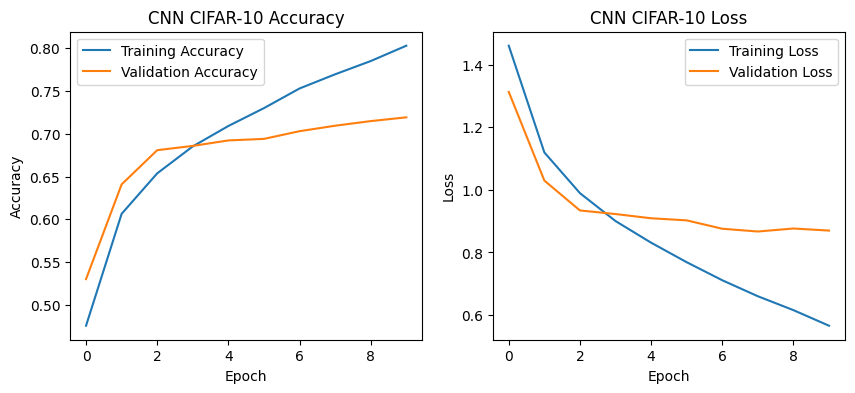

In [8]:
import pickle
import numpy as np

def unpickle(file):
    with open(file, 'rb') as fo:
        dict = pickle.load(fo, encoding='bytes')
    return dict

data_dir = '/content/cifar10_data/cifar-10-batches-py'
train_data = []
train_labels = []
for i in range(1, 6):
    batch = unpickle(f'{data_dir}/data_batch_{i}')
    train_data.append(batch[b'data'])
    train_labels.extend(batch[b'labels'])

x_train_cifar = np.concatenate(train_data).reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
y_train_cifar = np.array(train_labels)

test_batch = unpickle(f'{data_dir}/test_batch')
x_test_cifar = test_batch[b'data'].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
y_test_cifar = np.array(test_batch[b'labels'])
x_train_cifar, x_test_cifar = x_train_cifar/255.0, x_test_cifar/255.0

model_cifar = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(32,32,3)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model_cifar.compile(optimizer='adam',
                    loss='sparse_categorical_crossentropy',
                    metrics=['accuracy'])

history_cifar = model_cifar.fit(x_train_cifar, y_train_cifar,
                                epochs=10, validation_split=0.1)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history_cifar.history['accuracy'], label='Training Accuracy')
plt.plot(history_cifar.history['val_accuracy'], label='Validation Accuracy')
plt.title('CNN CIFAR-10 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history_cifar.history['loss'], label='Training Loss')
plt.plot(history_cifar.history['val_loss'], label='Validation Loss')
plt.title('CNN CIFAR-10 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

## D5 – Transfer Learning dengan VGG16

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Epoch 1/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.5179 - loss: 1.3786 - val_accuracy: 0.5826 - val_loss: 1.2087
Epoch 2/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.5837 - loss: 1.1978 - val_accuracy: 0.5912 - val_loss: 1.1625
Epoch 3/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.5998 - loss: 1.1411 - val_accuracy: 0.5968 - val_loss: 1.1446
Epoch 4/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.6178 - loss: 1.0992 - val_accuracy: 0.5996 - val_loss: 1.1358
Epoch 5/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.6280 - loss: 1.0632 - val_accuracy: 0.6076 - val_loss: 1.1070


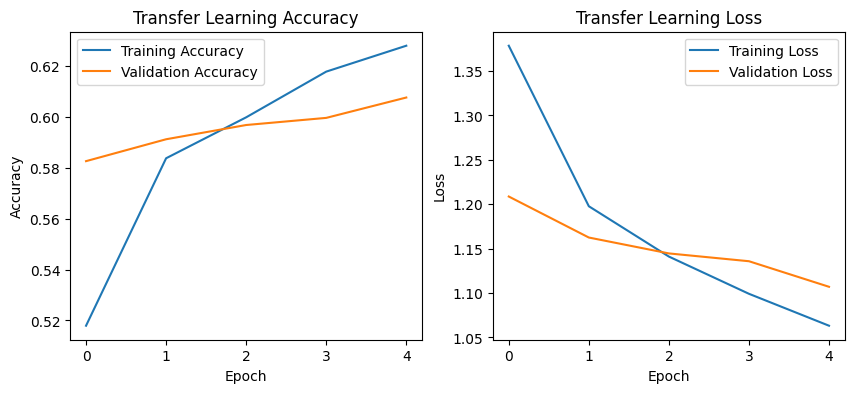

In [9]:
from tensorflow.keras.applications import VGG16

base_model = VGG16(weights='imagenet', include_top=False, input_shape=(32,32,3))
base_model.trainable = False

model_tl = models.Sequential([
    base_model,
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model_tl.compile(optimizer='adam',
                 loss='sparse_categorical_crossentropy',
                 metrics=['accuracy'])

history_tl = model_tl.fit(x_train_cifar, y_train_cifar,
                          epochs=5, validation_split=0.1)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history_tl.history['accuracy'], label='Training Accuracy')
plt.plot(history_tl.history['val_accuracy'], label='Validation Accuracy')
plt.title('Transfer Learning Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history_tl.history['loss'], label='Training Loss')
plt.plot(history_tl.history['val_loss'], label='Validation Loss')
plt.title('Transfer Learning Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

## D6 – Evaluasi dengan Confusion Matrix

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.99      0.98      0.98      1032
           3       0.99      0.98      0.98      1010
           4       0.99      0.98      0.99       982
           5       0.98      0.99      0.98       892
           6       0.99      0.99      0.99       958
           7       0.97      0.99      0.98      1028
           8       0.99      0.97      0.98       974
           9       0.98      0.98      0.98      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



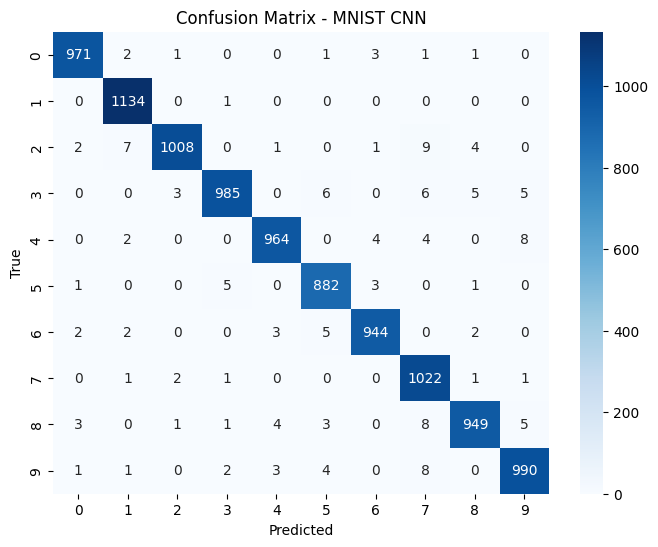

In [10]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

y_pred = model.predict(x_test_cnn).argmax(axis=1)

print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix - MNIST CNN')
plt.show()

## Fungsi Preprocessing

In [11]:
import numpy as np
from PIL import Image, ImageOps

def preprocess_to_mnist_28x28(img_pil):
    img = img_pil.convert('L')
    img = ImageOps.autocontrast(img)
    arr = np.array(img).astype(np.uint8)

    if arr.mean() > 127:
        img = ImageOps.invert(img)
        arr = np.array(img)

    thr = np.mean(arr) * 0.8
    mask = arr > thr
    if mask.any():
        ys, xs = np.where(mask)
        y0, y1 = ys.min(), ys.max()
        x0, x1 = xs.min(), xs.max()
        img = img.crop((x0, y0, x1+1, y1+1))

    img.thumbnail((20, 20), Image.Resampling.LANCZOS)
    w, h = img.size
    canvas = Image.new('L', (28, 28), color=0)
    canvas.paste(img, ((28 - w)//2, (28 - h)//2))

    arr = np.array(canvas).astype('float32') / 255.0
    arr = arr[..., None]
    return canvas, arr

## A. Prediksi dengan CNN

In [12]:
from google.colab import files
uploaded = files.upload()

Saving angka1.png to angka1.png


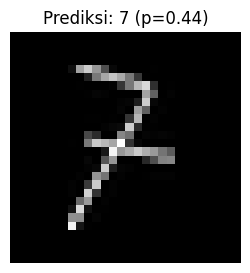

Rekap Prediksi CNN:
angka1.png -> 7 (p=0.437)


In [13]:
import matplotlib.pyplot as plt

results = []
for fname in uploaded.keys():
    img_pil = Image.open(fname)
    disp, x = preprocess_to_mnist_28x28(img_pil)
    x_batch = np.expand_dims(x, axis=0)
    probs = model.predict(x_batch, verbose=0)[0]
    pred = int(np.argmax(probs))
    conf = float(np.max(probs))
    results.append((fname, pred, conf))

    plt.figure(figsize=(3,3))
    plt.imshow(disp, cmap='gray')
    plt.title(f"Prediksi: {pred} (p={conf:.2f})")
    plt.axis('off')
    plt.show()

print("Rekap Prediksi CNN:")
for r in results:
    print(f"{r[0]} -> {r[1]} (p={r[2]:.3f})")

## B. Prediksi dengan SVM

In [14]:
from sklearn import svm
from sklearn.metrics import accuracy_score

x_train_flat = x_train.reshape(len(x_train), -1) / 255.0
x_test_flat = x_test.reshape(len(x_test), -1) / 255.0

clf = svm.SVC(kernel='rbf', gamma='scale', probability=True)
clf.fit(x_train_flat[:5000], y_train[:5000])
y_pred = clf.predict(x_test_flat)
print("Akurasi SVM:", accuracy_score(y_test, y_pred))

Akurasi SVM: 0.9513


In [15]:
from google.colab import files
uploaded = files.upload()

Saving angka1.png to angka1 (1).png


In [16]:
for fname in uploaded.keys():
    img_pil = Image.open(fname)
    _, x = preprocess_to_mnist_28x28(img_pil)
    x_flat = x.reshape(1, -1)
    pred = int(clf.predict(x_flat)[0])
    conf = None
    if hasattr(clf, "predict_proba"):
        conf = float(np.max(clf.predict_proba(x_flat)))
    print(f"{fname} -> Prediksi SVM: {pred}" + (f" (p={conf:.2f})" if conf else ""))

angka1 (1).png -> Prediksi SVM: 5 (p=0.34)
